# Expected R&D spend benchmark

**ML Zoomcamp 2026 midterm project**

**Goal:** predict the R&D spend we'd expect for a company, given its size, sector, profitability and location.
The prediction acts as a benchmark: is a company's reported R&D typical, unusually high or unusually low for its profile?

**Data:** EU Industrial R&D Investment Scoreboard panel (2003–2024), trimmed to the columns below.

| Column | Meaning |
|---|---|
| `company`, `company_name` | Short and long company name |
| `year` | Financial year |
| `new_country`, `region_12_new` | Country and world region of headquarters |
| `icb3_short`, `icb3_name` | Sector: 11 broad groups and 39 detailed sectors |
| `rnd_24` | **Target:** R&D investment, € million (2024 euros) |
| `netsales_24`, `capex_24`, `profit_24`, `mcap_24` | Net sales, capital expenditure, operating profit, market cap (€m, 2024 euros) |
| `emp` | Number of employees |
| `year_inc_new` | Year of incorporation (useful for company age) |

## 1. Setup and load data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/scoreboard_panel.csv')
df.head()

,company,company_name,year,new_country,region_12_new,icb3_short,icb3_name,rnd_24,netsales_24,emp,capex_24,profit_24,mcap_24,year_inc_new
0,AMAZON,"AMAZON.COM, INC.",2024,US,US,ICT software,Software & Computer Services,65318.281985,614071.614207,1556000.0,79891.231110,66024.641448,2.220511e+06,1994.0
1,ALPHABET,ALPHABET INC.,2024,US,US,ICT software,Software & Computer Services,46131.485225,336912.118587,183323.0,50567.908365,108181.730677,1.064665e+06,1998.0
2,META,"META PLATFORMS, INC.",2024,US,US,ICT software,Software & Computer Services,41985.754163,158341.515064,74067.0,35861.006834,66407.738955,1.228620e+06,2004.0
3,MICROSOFT,MICROSOFT CORPORATION,2024,US,US,ICT software,Software & Computer Services,31271.537203,271175.281548,228000.0,62133.987872,123715.468284,2.834358e+06,1981.0
4,APPLE,APPLE INC.,2024,US,US,ICT hardware,Technology Hardware & Equipment,30195.398980,376393.300606,164000.0,9093.271730,118602.367889,3.164133e+06,1977.0


## 2. Data cleaning

Things to look at:
- How many rows have a missing target (`rnd_24`)? These can't be used for training.
- Are there zero or negative values in R&D, sales, capex? What should happen to them?
- Missing values in the features: fill (with what?) or drop?
- Hint: `df.isnull().mean()` gives the share missing per column.

In [3]:
# How big is the data, and how much is missing?
print(df.shape)
df.isnull().mean().round(3)

(96836, 14)


company          0.000
company_name     0.000
year             0.000
new_country      0.000
region_12_new    0.000
icb3_short       0.001
icb3_name        0.001
rnd_24           0.186
netsales_24      0.153
emp              0.217
capex_24         0.233
profit_24        0.139
mcap_24          0.372
year_inc_new     0.000
dtype: float64

**Size and missing values**

The dataset has 96,836 rows (one per company per year) and 14 columns.

- **Target (`rnd_24`):** 18.6% of rows have no R&D figure. These rows can't be used to train the model, so they will be dropped.
- **Financial features:** missing values range from 14% (`profit_24`) to 23% (`capex_24`). Market capitalisation (`mcap_24`) is missing in 37% of rows, probably because not all companies are listed on a stock exchange.
- **Categorical features:** company, year, country, region and sector are almost complete (sector is missing in 0.1% of rows).

Many of the rows missing the target may also be missing other figures, so I'll check the missing values again after dropping them.

In [4]:
# How many rows can’t be used because the target is missing or not positive?
print('Missing R&D:', df['rnd_24'].isnull().sum())
print('Zero or negative R&D:', (df['rnd_24'] <= 0).sum())

Missing R&D: 18039
Zero or negative R&D: 228


**Unusable target values**

- 18,039 rows have no R&D figure.
- 228 rows have zero or negative R&D. Negative R&D isn't possible, and companies with zero R&D shouldn't appear in a scoreboard of top R&D investors, so these are most likely reporting errors. They would also break the log transform used for the target later.

Both groups will be dropped, leaving 78,569 rows.

In [6]:
# Are there odd values in the numbers?
pd.set_option('display.float_format', '{:,.1f}'.format)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"96,836.0","2,013.4",5.7,"2,003.0","2,009.0","2,013.0","2,018.0","2,024.0"
rnd_24,"78,797.0",210.2,"1,019.6",0.0,12.7,36.9,104.8,"65,318.3"
netsales_24,"82,033.0","5,927.0","176,126.3",-9.0,159.2,766.6,"3,077.7","50,140,463.0"
emp,"75,861.0","16,981.3","46,059.9",0.0,757.0,"3,705.0","12,834.0","1,608,000.0"
capex_24,"74,245.0",374.4,"1,773.3",-716.1,5.9,33.8,153.7,"79,891.2"
profit_24,"83,386.0",565.9,"5,764.9","-35,339.6",0.2,45.2,248.0,"1,314,803.2"
mcap_24,"60,795.0","9,129.6","51,808.0",0.0,367.0,"1,327.6","4,797.1","3,164,133.0"
year_inc_new,"96,826.0","1,979.4",38.5,"1,654.0","1,968.0","1,995.0","2,003.0","2,023.0"


**Value ranges and outliers**

All money columns are in € millions, converted by the Scoreboard from each company's reporting currency (36 currencies) at the end-2024 exchange rate.

- The typical (median) company spends €37m a year on R&D on sales of about €770m. The averages are much higher (€210m R&D) because a few very large companies pull them up. R&D, sales, employees and capex are all heavily right-skewed, so they will be log-transformed.
- **Data error:** the largest net sales figure (€50 trillion, Ecopetrol, 2015) is impossible. In the original file, Ecopetrol's 2015 figures are in Colombian pesos but labelled as US dollars, so they were converted at the wrong exchange rate. This row has zero R&D, so it is removed with the other zero-R&D rows.
- **Negative values:** 14 rows have negative net sales and 27 have negative capex, which isn't possible. These will be treated as missing values. Negative operating profit is genuine (loss-making companies) and is kept.
- **Zero sales:** 1,280 rows have zero net sales. These are likely early-stage companies (e.g. biotech) investing in R&D before generating revenue, so they are kept.
- **Year of incorporation** ranges from 1654 to 2023. The earliest (Orkla, Norway) is genuine.

In [8]:
# Keep only rows with a positive R&D figure (this also drops missing values)
df_clean = df[df['rnd_24'] > 0].copy()

# Negative sales and capex aren't possible: treat them as missing
for col in ['netsales_24', 'capex_24']:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

print(df_clean.shape)
(df_clean.isnull().mean() * 100).round(1)

(78569, 14)


company          0.0
company_name     0.0
year             0.0
new_country      0.0
region_12_new    0.0
icb3_short       0.0
icb3_name        0.0
rnd_24           0.0
netsales_24      3.0
emp              9.8
capex_24        10.7
profit_24        1.6
mcap_24         25.4
year_inc_new     0.0
dtype: float64

**Cleaning**

- Dropped the rows with missing, zero or negative R&D, leaving 78,569 rows.
- Replaced negative net sales and capex values with missing values.

Most of the missing feature values were in the rows without an R&D figure. After cleaning, net sales and profit are almost complete (3% and 2% missing), employees and capex are about 10% missing, and market capitalisation is still 25% missing. The remaining gaps will be filled before training. Tree-based models such as XGBoost can also handle missing values directly.

## 3. Exploratory data analysis

### 3.1 The target
- Plot the distribution of `rnd_24`. It's very skewed: compare it with `np.log1p(rnd_24)`.
- Min, max, median. Which companies are at the extremes?

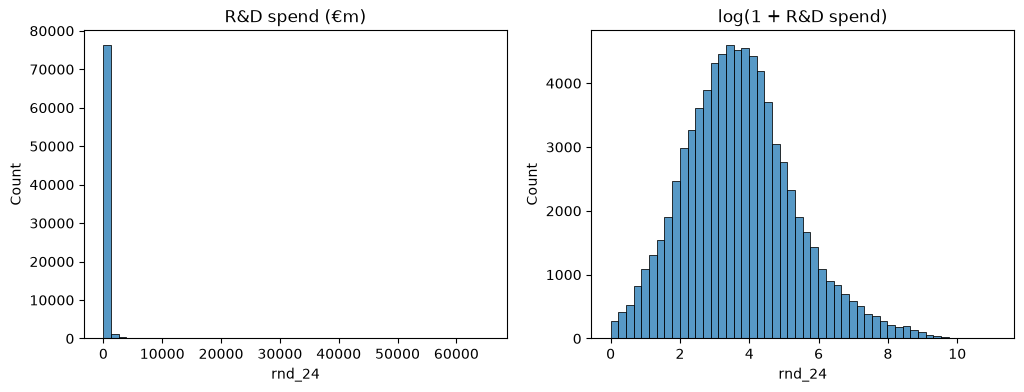

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean['rnd_24'], bins=50, ax=axes[0])
axes[0].set_title('R&D spend (€m)')

sns.histplot(np.log1p(df_clean['rnd_24']), bins=50, ax=axes[1])
axes[1].set_title('log(1 + R&D spend)')

plt.show()

**Target distribution**

R&D spend is extremely right-skewed: most companies spend tens of millions of euros a year, but a few spend tens of billions (the maximum is Amazon, €65bn in 2024). On a normal scale almost all rows fall into a single bar.

After a log transform (`np.log1p`), the distribution is close to bell-shaped, centred around 3.6 (about €37m). The model will therefore predict log R&D spend, and predictions will be converted back to euros with `np.expm1`.

### 3.2 Features: ranges and distributions
- `describe()` on the numeric columns. Which ones also need a log transform?
- How many companies per sector, region and year?
- How many years does each company appear in? (Hint: `groupby('company')['year'].nunique()`)

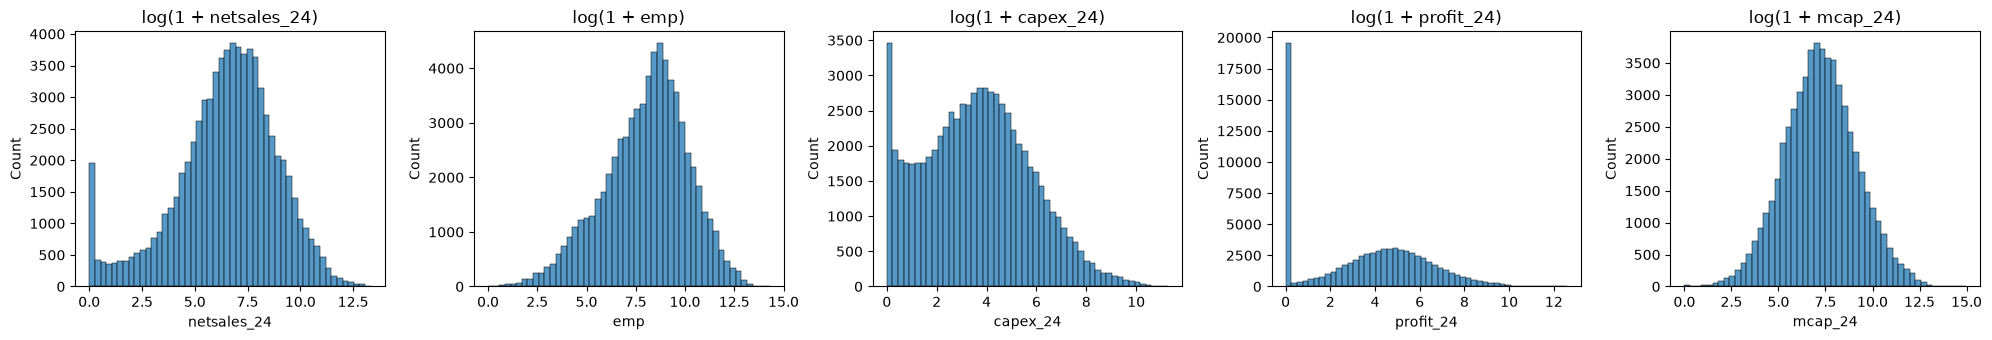

icb3_short
Health                      15536
ICT hardware                14917
Others                      10917
Industrials                  9881
ICT software                 9844
Automotive                   4844
Chemicals                    3896
Energy                       2564
Construction & Materials     2398
Financial                    2387
Aerospace & Defence          1346
Name: count, dtype: int64 

region_12_new
US       21560
EU       21264
ROW      15192
China    11940
Japan     8613
Name: count, dtype: int64 

count   6,295.0
mean       12.5
std         6.0
min         1.0
25%         8.0
50%        12.0
75%        18.0
max        22.0
Name: year, dtype: float64


In [11]:
num_cols = ['netsales_24', 'emp', 'capex_24', 'profit_24', 'mcap_24']

# Distributions of the numeric features on a log scale
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(np.log1p(df_clean[col].clip(lower=0)), bins=50, ax=ax)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

# How the rows split by sector and region
print(df_clean['icb3_short'].value_counts(), '\n')
print(df_clean['region_12_new'].value_counts(), '\n')

# How many years each company appears in
years_per_company = df_clean.groupby('company')['year'].nunique()
print(years_per_company.describe())

**Feature distributions**

- **Net sales, employees and market capitalisation** are right-skewed like the target and look bell-shaped after a log transform, so they will be log-transformed.
- **Net sales** has a small spike at zero (about 2,600 rows with sales under €1m): early-stage companies investing in R&D before earning revenue.
- **Capex** also has many very small values (about 7,300 rows under €1m), typical of software and biotech companies that invest in people rather than physical assets.
- **Operating profit** can't be log-transformed directly because 24.5% of rows are loss-making. It will be used as a **profit margin** (profit ÷ sales) instead. Losses are most common in Health (55% of rows) and ICT software (31%), sectors where companies often invest heavily in R&D before generating profits.

**Sectors and regions**

All 11 sectors are well represented (from 1,346 rows for Aerospace & Defence to 15,536 for Health). The five regions are the US, EU, China, Japan and "rest of world" (ROW), which includes the UK.

**Years per company**

The 6,295 companies appear in 12 years on average (up to 22). Because each company appears many times, the train/test split must keep each company's rows together, otherwise the model would be tested on companies it has already seen.

### 3.3 R&D intensity by sector
- R&D intensity = R&D ÷ net sales. Compare the median by sector with a bar or box plot.
- Look at the extreme cases (intensity above 100%). What kind of companies are they?

### 3.4 Feature importance
- Correlation of each numeric feature with log R&D (after log-transforming the skewed ones).
- Mutual information for the categorical features (sector, region), as in the churn homework.
- Which features look most useful? Any that look useless?

## 4. Feature engineering and validation split

Ideas for features: log of the money columns, profit margin (profit ÷ sales), company age (year − year of incorporation).

**Two traps to avoid:**
1. **Leakage:** never use anything calculated from R&D spend as a feature.
2. **The same company in train and test:** a random split puts a company's 2019 row in training and its 2020 row in test, which flatters the score.
   Use a split by time (e.g. train ≤ 2019, validation 2020–21, test 2022–24) or by company (`GroupShuffleSplit`).
   Write down which you chose and why.

## 5. Model training

Metric: RMSE on log R&D (and, for interpretation, `np.exp(rmse)` = the typical "factor" the prediction is off by).

### 5.1 Baseline: linear model
- `DictVectorizer` + `Ridge` (or `LinearRegression`). Tune the regularisation strength `alpha`.

### 5.2 Decision tree
- Tune `max_depth` and `min_samples_leaf`, as in HW6.

### 5.3 Random forest
- Tune `n_estimators`, `max_depth`, `min_samples_leaf`.

### 5.4 XGBoost
- Tune `eta`, `max_depth`, `min_child_weight`. Use the validation set to pick the number of rounds.

### 5.5 Comparison
- A small table of validation RMSE for each tuned model. Pick the best one and say why.

## 6. Final model
- Retrain the chosen model on train + validation, evaluate once on the test set.
- Try predicting for one example company and compare with its actual R&D.